# RF coursework
------------------------------------------------------------------------

In [108]:
import numpy as np 
import scipy 
import matplotlib.pyplot as plt
import skrf as rf
import schemdraw


print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("scikit-rf:", rf.__version__)
print("Dependencies working correctly.")

NumPy: 2.4.6
SciPy: 1.17.1
scikit-rf: 2.2.0
Dependencies working correctly.


## L network at 100MHz with Capacitor as the Shunt

### Network building function

In [ ]:
def buildMatchingLowPassNetwork(f_start = 50, f_stop = 150, f_step = 1, unit = 'MHz', Z_0 = 50, L_match = 96e-9, C_match = 26e-12, R_load = 75, L_load = 95.49e-9):
    """ 
    Build a matching network using a series inductor and parallel capacitor (shunt) to match a load impedance to a source impedance. Low pass filter.
    """
    points = int((f_stop-f_start)/f_step)+1 # number of points in frequency sweep
    frequency = rf.Frequency(start=f_start, stop=f_stop, npoints=points, unit=unit) # in MHz

    f = frequency.f # frequency in MHz
    omega = 2*np.pi*f

    # load branch: Series R-L with R = 75 ohm, L = 95.49 nH for 75 + j60 ohms load impedence 
    Z_load = R_load + 1j*omega*L_load # load impedance

    #Capacitor matching branch:
    Z_C = 1 / (1j * omega * C_match) # impedance of capacitor

    #Z of the matching network: Series R-L in parallel with C
    Z_parallel = Z_load * Z_C / (Z_load + Z_C) # parallel combination of load and capacitor

    # Series inductor matching branch:
    Z_L = 1j * omega * L_match # impedance of inductor

    #Input impedance of matching network:
    Z_in = Z_parallel + Z_L # input impedance of matching network

    #Z matrix:
    Z_matrix = Z_in [:, np.newaxis, np.newaxis] # convert to 3D array for skrf compatibility

    network = rf.Network(frequency=frequency, z = Z_matrix, z0=Z_0) # create skrf network object

    return network

lp_network = buildMatchingLowPassNetwork()
print("Low pass matching network created successfully.")
print("Network ports",  lp_network.nports)
print("Network frequency points", len(lp_network.f))

Low pass matching network created successfully.
Network ports 1
Network frequency points 101


### S11 vs Frequency:

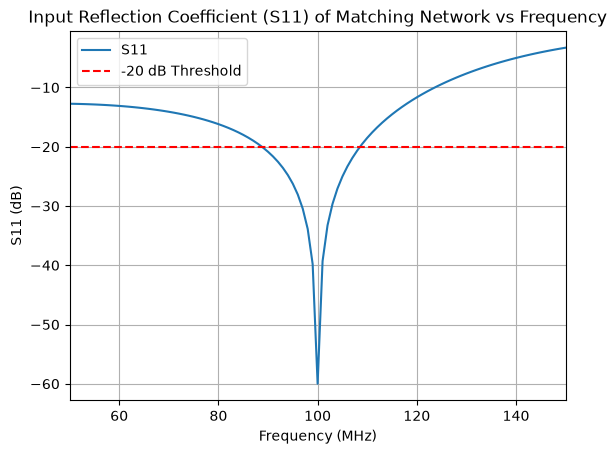

In [110]:
fig, ax = plt.subplots()

lp_network.plot_s_db(m=0, n=0, ax=ax)
ax.set_title("Input Reflection Coefficient (S11) of Matching Network vs Frequency")
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("S11 (dB)")
ax.axhline(-20, color='r', linestyle='--', label='-20 dB Threshold')
ax.legend()
ax.grid(True)

plt.show()

### Smith Charts:

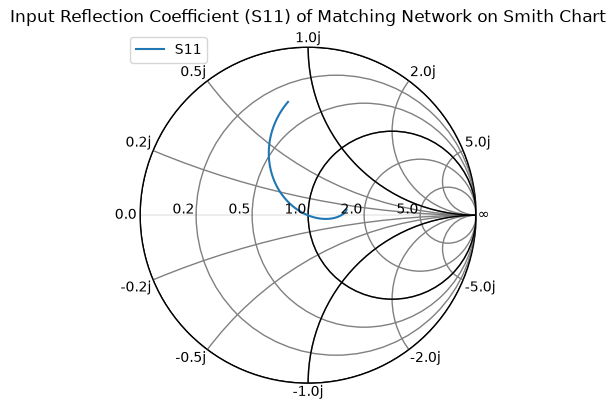

In [111]:
fig, ax = plt.subplots()
lp_network.plot_s_smith(draw_labels=True, m=0, n=0, ax=ax)
ax.set_title("Input Reflection Coefficient (S11) of Matching Network on Smith Chart")
plt.show()

## High pass filter design at 100 MHz:

In [112]:
def buildMatchingHighPassNetwork(f_start = 50, f_stop = 150, f_step = 1, unit = 'MHz', Z_0 = 50, L_match = 96e-9, C_match = 26e-12, R_load = 75, L_load = 95.49e-9):
    """ 
    Build a matching network using a series capacitor and parallel inductor (shunt) to match a load impedance to a source impedance. High pass filter.
    """


    points = int((f_stop-f_start)/f_step)+1 # number of points in frequency sweep
    frequency = rf.Frequency(start=f_start, stop=f_stop, npoints=points, unit=unit) # in MHz

    f = frequency.f # frequency in MHz
    omega = 2*np.pi*f

    # load branch: Series R-L with R = 75 ohm, L = 95.49 nH for 75 + j60 ohms load impedence 
    Z_load = R_load + 1j*omega*L_load # load impedance

    #Shunt inductor matching branch:
    Z_L = 1j * omega * L_match # impedance of inductor

    #Z of the matching network: Series R-L in parallel with C
    Z_parallel = Z_load * Z_L / (Z_load + Z_L) # parallel combination of load and inductor


    # Series capacitor matching branch:
    Z_C = 1 / (1j * omega * C_match) # impedance of capacitor

    #Input impedance of matching network:
    Z_in = Z_parallel + Z_C # input impedance of matching network

    #Z matrix:
    Z_matrix = Z_in [:, np.newaxis, np.newaxis] # convert to 3D array for skrf compatibility

    network = rf.Network(frequency=frequency, z = Z_matrix, z0=Z_0) # create skrf network object

    return network

hp_network = buildMatchingHighPassNetwork()
print("High pass matching network created successfully.")
print("Network ports",  hp_network.nports)
print("Network frequency points", len(hp_network.f))



High pass matching network created successfully.
Network ports 1
Network frequency points 101


### S11 vs Frequency:

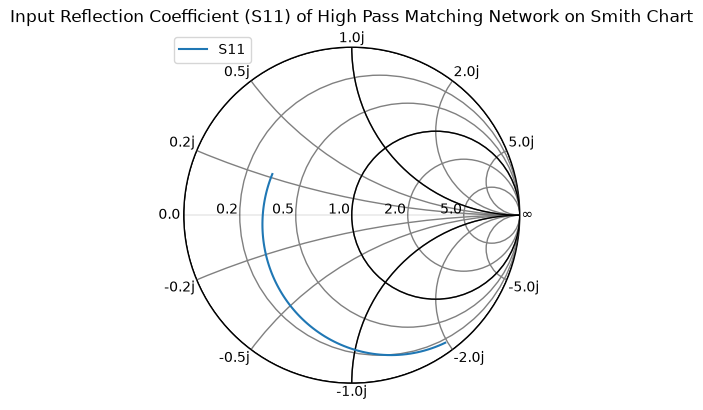

In [113]:
fig, ax = plt.subplots()
hp_network.plot_s_smith(draw_labels=True, m=0, n=0, ax=ax)
ax.set_title("Input Reflection Coefficient (S11) of High Pass Matching Network on Smith Chart")
plt.show()

### Tuning the network:

In [114]:

import ipywidgets as widgets
from IPython.display import display, clear_output

def tuneHighPassNetwork(
    L_match_nH=479.20,
    C_match_pF=26.34,
    R_load=75,
    L_load_nH=95.49
):

    # Convert slider values into SI units
    L_match = L_match_nH * 1e-9
    C_match = C_match_pF * 1e-12
    L_load = L_load_nH * 1e-9

    # Build scikit-rf network
    network = buildMatchingHighPassNetwork(
        L_match=L_match,
        C_match=C_match,
        R_load=R_load,
        L_load=L_load
    )

    # Extract S11 from the network
    s11_db = network.s_db[:, 0, 0]
    frequency_mhz = network.f / 1e6

    # Locate minimum S11
    min_index = np.argmin(s11_db)

    min_frequency = frequency_mhz[min_index]
    min_s11 = s11_db[min_index]

    # Find frequencies where S11 crosses -20 dB
    threshold = -20

    crossings = np.where(
        np.diff(np.sign(s11_db - threshold))
    )[0]

    crossing_frequencies = []

    for index in crossings:

        f1 = network.f[index]
        f2 = network.f[index + 1]

        s1 = s11_db[index]
        s2 = s11_db[index + 1]

        # Linear interpolation
        f_cross = f1 + (threshold - s1) * (f2 - f1) / (s2 - s1)

        crossing_frequencies.append(f_cross / 1e6)

    # Plot frequency response and Smith chart
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    # S11 frequency response
    ax1.plot(
        frequency_mhz,
        s11_db,
        linewidth=2,
        label="S11"
    )

    ax1.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="-20 dB threshold"
    )

    ax1.axvline(
        min_frequency,
        linestyle=":",
        label=f"Minimum at {min_frequency:.2f} MHz"
    )

    # Mark -20 dB crossing points
    for frequency in crossing_frequencies:

        ax1.axvline(
            frequency,
            color="green",
            linestyle=":",
            alpha=0.7
        )

        ax1.plot(
            frequency,
            threshold,
            "go"
        )

    ax1.set_xlabel("Frequency (MHz)")
    ax1.set_ylabel("S11 (dB)")
    ax1.set_title("High-Pass Matching Network")
    ax1.grid(True)
    ax1.legend()

    # Smith chart
    network.plot_s_smith(draw_labels=True, ax=ax2)
    ax2.set_title("Smith Chart")

    plt.tight_layout()
    plt.show()

    # Display numerical results
    print(f"Matching inductance: {L_match_nH:.2f} nH")
    print(f"Matching capacitance: {C_match_pF:.2f} pF")
    print(f"Load resistance: {R_load:.2f} Ω")
    print(f"Load inductance: {L_load_nH:.2f} nH \n")
   

    print(f"Minimum S11: {min_s11:.2f} dB")
    print(f"Frequency of minimum: {min_frequency:.2f} MHz")
    print(f"Reflected power: {10**(min_s11/10)*100:.6f} % \n")

    
    print("-20 dB crossing frequencies:")

    if len(crossing_frequencies) == 0:

        print("No crossings within the selected frequency range.")

        if np.all(s11_db <= threshold):
            print("The entire frequency range meets the -20 dB criterion.")
        else:
            print("The network does not meet the -20 dB criterion.")

    else:

        for i, frequency in enumerate(crossing_frequencies, start=1):
            print(f"Crossing {i}: {frequency:.2f} MHz")

        if len(crossing_frequencies) == 2:

            bandwidth = crossing_frequencies[1] - crossing_frequencies[0]

            
            print(f"Operational bandwidth: {bandwidth:.2f} MHz")
            print(
                f"Lower frequency: {crossing_frequencies[0]:.2f} MHz"
            )
            print(
                f"Upper frequency: {crossing_frequencies[1]:.2f} MHz"
            )


In [115]:
widgets.interact(
    tuneHighPassNetwork,

    L_match_nH=widgets.FloatSlider(
        value=479.20,
        min=10,
        max=1000,
        step=0.01,
        description="L match (nH)",
        continuous_update=False
    ),

    C_match_pF=widgets.FloatSlider(
        value=26.34,
        min=1,
        max=150,
        step=0.01,
        description="C match (pF)",
        continuous_update=False
    )
);

interactive(children=(FloatSlider(value=479.2, continuous_update=False, description='L match (nH)', max=1000.0…